# Statistical Testing on E-Commerce Data

**Name:** Ahmadreza Jafari
**Student ID:** 403222080
**Course:** Data Science — Shahid Beheshti University, Winter 2026
**Instructor:** Dr. Kheradpisheh



This notebook implements the six required hypothesis tests (Part I of the assignment) on invoice-level
online retail data: product, quantity, price, customer, and country information. Each test states a
question, hypotheses, the chosen test, its result, and an interpretation in context.columns
`Quantity`, `UnitPrice`, `Country`, and an invoice identifier; column names are normalised to
`snake_case` immediately after loading.


## 0. Imports and configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['figure.dpi'] = 100

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
ALPHA = 0.05  # conventional significance level used throughout

DATA_PATH = 'data.csv'


## 1. Data loading and basic preparation

In [2]:
# The raw file is commonly distributed with latin-1 encoding.
raw = pd.read_csv(DATA_PATH, encoding='latin-1')

# Normalise column names to snake_case. Map known camelCase names explicitly
# first (CustomerID -> customer_id), then apply the general lowercasing rule,
# to avoid the regex splitting "ID" into "i_d".
raw = raw.rename(columns={
    'CustomerID': 'customer_id',
    'InvoiceNo': 'invoice_no',
    'StockCode': 'stock_code',
    'UnitPrice': 'unit_price',
    'InvoiceDate': 'invoice_date',
})
raw.columns = raw.columns.str.strip().str.replace(' ', '_').str.lower()
print(raw.columns.tolist())
raw.head()

['invoice_no', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country']


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   invoice_no    541909 non-null  str    
 1   stock_code    541909 non-null  str    
 2   description   540455 non-null  str    
 3   quantity      541909 non-null  int64  
 4   invoice_date  541909 non-null  str    
 5   unit_price    541909 non-null  float64
 6   customer_id   406829 non-null  float64
 7   country       541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [ ]:
raw.describe(include='number').T


,count,mean,std,min,25%,50%,75%,max
quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
unit_price,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
customer_id,406829.0,15287.690570,1713.600303,12346.00,13953.00,15152.00,16791.00,18287.0


In [5]:
# Restrict to rows with positive quantity and positive unit price
# (negative/zero quantity or price typically indicate returns, adjustments, or data errors).
df = raw[(raw['quantity'] > 0) & (raw['unit_price'] > 0)].copy()

# Derived variable: revenue
df['revenue'] = df['quantity'] * df['unit_price']

print(f'Rows before filtering: {len(raw):,}')
print(f'Rows after filtering (quantity > 0 and unit_price > 0): {len(df):,}')
df[['quantity', 'unit_price', 'revenue', 'country']].describe(include='all').T


Rows before filtering: 541,909
Rows after filtering (quantity > 0 and unit_price > 0): 530,104


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
quantity,530104.0,NaN,NaN,NaN,10.542037,155.524124,1.0,1.0,3.0,10.0,80995.0
unit_price,530104.0,NaN,NaN,NaN,3.907625,35.915681,0.001,1.25,2.08,4.13,13541.33
revenue,530104.0,NaN,NaN,NaN,20.121871,270.356743,0.001,3.75,9.9,17.7,168469.6
country,530104,38,United Kingdom,485123,NaN,NaN,NaN,NaN,NaN,NaN,NaN


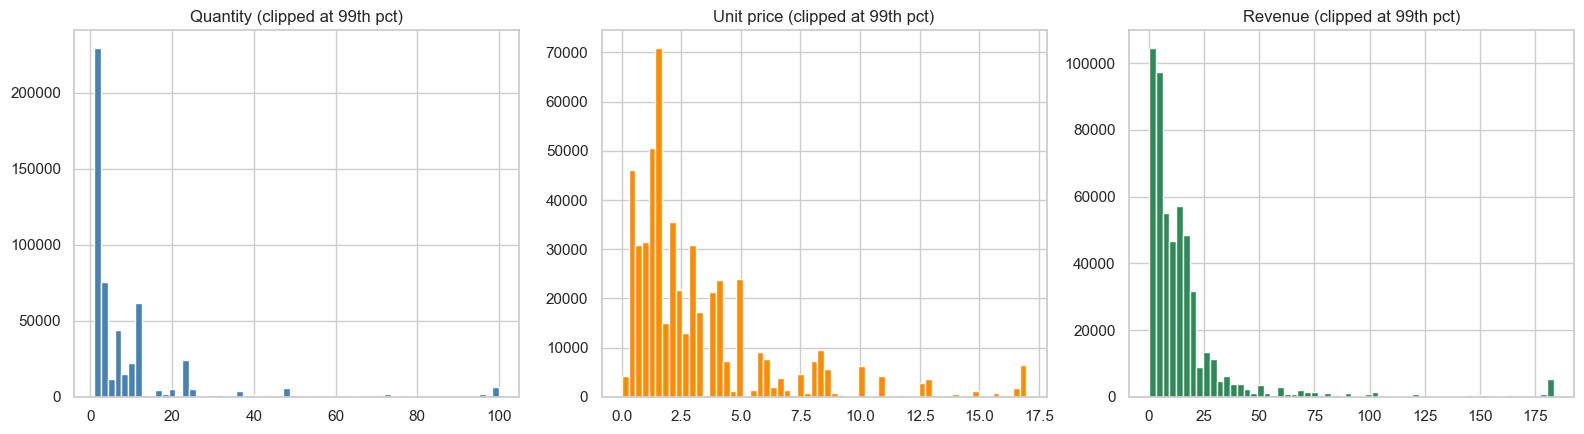

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df['quantity'].clip(upper=df['quantity'].quantile(0.99)).hist(bins=60, ax=axes[0], color='steelblue')
axes[0].set_title('Quantity (clipped at 99th pct)')

df['unit_price'].clip(upper=df['unit_price'].quantile(0.99)).hist(bins=60, ax=axes[1], color='darkorange')
axes[1].set_title('Unit price (clipped at 99th pct)')

df['revenue'].clip(upper=df['revenue'].quantile(0.99)).hist(bins=60, ax=axes[2], color='seagreen')
axes[2].set_title('Revenue (clipped at 99th pct)')

plt.tight_layout()
plt.show()


**Data description.** The raw file holds 541,909 invoice-level rows across 8 columns
(`invoice_no`, `stock_code`, `description`, `quantity`, `invoice_date`, `unit_price`,
`customer_id`, `country`). After restricting to rows with strictly positive `quantity`
and `unit_price` (dropping returns/cancellations and data-entry errors), the working
dataset contains **530,104 rows**, spanning **38 distinct countries** and **4,338 distinct
customers**. The dataset is overwhelmingly dominated by the **United Kingdom**, which
accounts for **91.5%** of line items (485,123 of 530,104). `quantity`, `unit_price`, and the
derived `revenue = quantity x unit_price` are all strongly right-skewed: the median revenue
is GBP 9.90 while the mean is GBP 20.12, pulled up by a long tail of large bulk orders
(maximum quantity 80,995; maximum revenue GBP 168,469.60). The histograms above clip at
the 99th percentile purely for visualisation; the heavy tail is visible in `describe()`.

---
## Test 1: Normality of revenue (Shapiro-Wilk)

**Question:** does the distribution of line-item revenue resemble a normal distribution?

**Hypotheses:**
- $H_0$: the sampled revenue values come from a normal distribution.
- $H_1$: the sampled revenue values do not come from a normal distribution.


Shapiro-Wilk statistic = 0.3038, p-value = 5.96584e-75


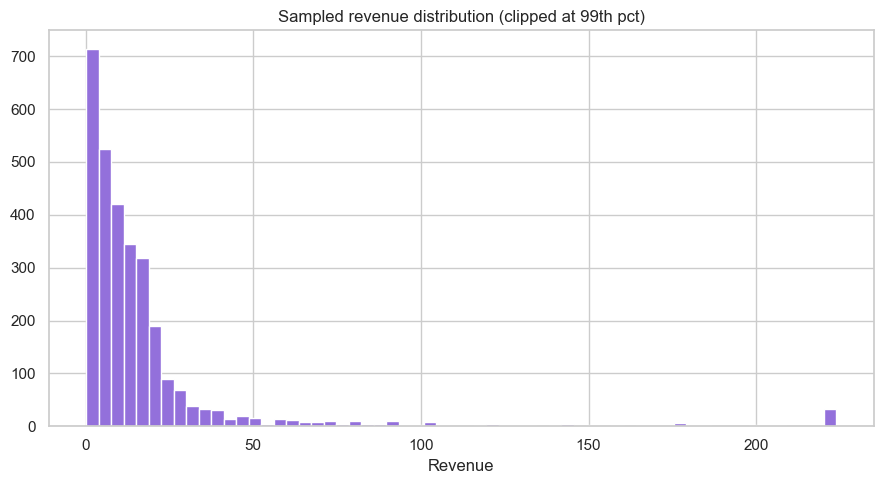

In [7]:
sample_revenue = df['revenue'].sample(n=min(3000, len(df)), random_state=RANDOM_SEED)

shapiro_stat, shapiro_p = stats.shapiro(sample_revenue)
print(f'Shapiro-Wilk statistic = {shapiro_stat:.4f}, p-value = {shapiro_p:.6g}')

fig, ax = plt.subplots()
sample_revenue.clip(upper=sample_revenue.quantile(0.99)).hist(bins=60, ax=ax, color='mediumpurple')
ax.set_title('Sampled revenue distribution (clipped at 99th pct)')
ax.set_xlabel('Revenue')
plt.tight_layout()
plt.show()


**Interpretation.** The Shapiro-Wilk statistic is W = 0.3038 with a p-value of
approximately 5.97 x 10^-75, far below alpha = 0.05, so we **reject H0**: the sampled revenue
values do not come from a normal distribution. This is exactly as expected - revenue is a
strictly positive quantity formed as the product of two positive, right-skewed variables, so
its distribution is heavily right-skewed with a long upper tail, as the histogram confirms.
The practical implication is that later tests which formally assume approximate normality of
the response within groups (the two-sample t-test in Test 3 and the one-way ANOVA in Test 4)
are applied to a non-normal response. They are reasonably robust to this violation at the very
large sample sizes here (hundreds of thousands of observations per group), but the result
should still be interpreted with some caution, and it motivates the non-parametric
Mann-Whitney U test added as Test 6. The non-parametric tests (Spearman in Test 2, chi-square
in Test 5) do not rely on a normality assumption at all.

---
## Test 2: Association between quantity and unit price (Spearman)

**Question:** is there an association between quantity ordered and unit price?

**Hypotheses:**
- $H_0$: there is no monotonic association between quantity and unit price.
- $H_1$: there is a monotonic association between quantity and unit price.


Spearman correlation = -0.4032, p-value = 0


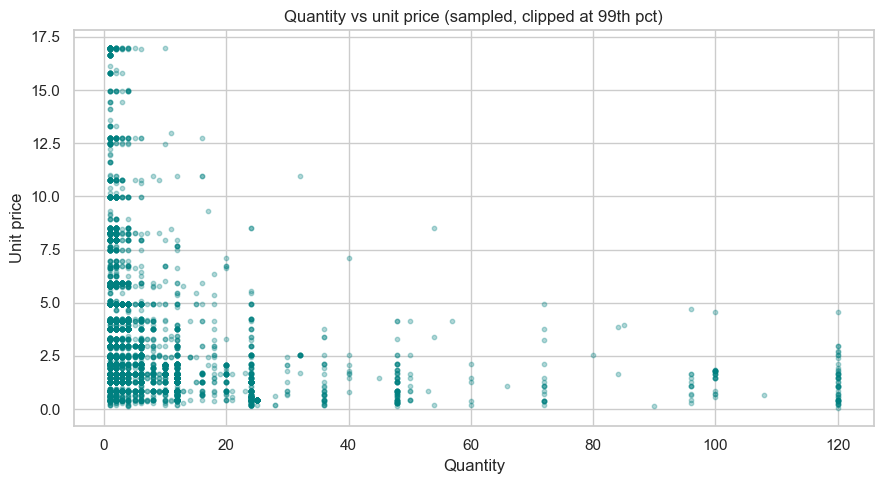

In [8]:
spearman_corr, spearman_p = stats.spearmanr(df['quantity'], df['unit_price'])
print(f'Spearman correlation = {spearman_corr:.4f}, p-value = {spearman_p:.6g}')

fig, ax = plt.subplots()
sample_qp = df[['quantity', 'unit_price']].sample(n=min(5000, len(df)), random_state=RANDOM_SEED)
ax.scatter(sample_qp['quantity'].clip(upper=sample_qp['quantity'].quantile(0.99)),
           sample_qp['unit_price'].clip(upper=sample_qp['unit_price'].quantile(0.99)),
           alpha=0.3, s=10, color='teal')
ax.set_xlabel('Quantity')
ax.set_ylabel('Unit price')
ax.set_title('Quantity vs unit price (sampled, clipped at 99th pct)')
plt.tight_layout()
plt.show()


**Interpretation.** The Spearman rank correlation is r_s = -0.4032 with a p-value
that is effectively 0 (smaller than machine precision), so we **reject H0**: there is a
statistically significant monotonic association between quantity and unit price. The sign is
**negative**, meaning that customers tend to buy larger quantities of cheaper items and smaller
quantities of more expensive items - consistent with bulk-buying of low-cost goods and
smaller basket sizes for high-unit-price items. In terms of magnitude, |r_s| = 0.40 is a
**moderate** association (not weak, but far from the near-perfect monotone relationships seen
in physical data). With ~530,000 observations the test has enormous power, so statistical
significance is essentially guaranteed; the more meaningful observation is that the effect
size is moderate rather than strong, suggesting pricing and purchase quantity are related but
not deterministically so.

---
## Test 3: Revenue difference between the United Kingdom and other countries (two-sample t-test)

**Question:** do line-item revenues differ on average between the United Kingdom and all other
countries combined?

**Hypotheses:**
- $H_0$: mean revenue for UK transactions equals mean revenue for non-UK transactions.
- $H_1$: mean revenue for UK transactions differs from mean revenue for non-UK transactions.


In [9]:
uk_revenue = df.loc[df['country'] == 'United Kingdom', 'revenue']
other_revenue = df.loc[df['country'] != 'United Kingdom', 'revenue']

print(f'UK: n={len(uk_revenue):,}, mean={uk_revenue.mean():.2f}, std={uk_revenue.std():.2f}')
print(f'Other: n={len(other_revenue):,}, mean={other_revenue.mean():.2f}, std={other_revenue.std():.2f}')

# Welch's t-test (does not assume equal variances) is used as the default, safer choice
# given the very different group sizes and likely unequal variances.
t_stat, t_p = stats.ttest_ind(uk_revenue, other_revenue, equal_var=False)
print(f"Welch's t-statistic = {t_stat:.4f}, p-value = {t_p:.6g}")


UK: n=485,123, mean=18.60, std=281.28
Other: n=44,981, mean=36.49, std=88.38
Welch's t-statistic = -30.8258, p-value = 4.99853e-208


**Interpretation.** The **non-UK** group has the higher mean revenue per line item:
GBP 36.49 (n = 44,981) versus GBP 18.60 for the UK (n = 485,123). Welch's t-statistic is
t = -30.83 with a p-value of approximately 5.0 x 10^-208, so we **reject H0** at alpha = 0.05 -
the difference in mean line-item revenue between the UK and the rest of the world is
statistically significant. The direction makes commercial sense: the retailer is UK-based, so
UK transactions are dominated by high volume of smaller everyday orders, while non-UK
transactions (especially EIRE, see Test 4) tend to be larger wholesale-style line items.
Because the UK sample is so large, even a modest absolute difference is highly significant; the
GBP 17.89 gap in means is also practically meaningful in currency terms - non-UK line items are
on average nearly twice as valuable as UK ones. We note that the very large standard deviations
(281 and 88) relative to the means reflect the extreme right skew established in Test 1, which
is why the non-parametric Test 6 is the more robust comparison.

---
## Test 4: Revenue across top countries (one-way ANOVA)

**Question:** among the top countries by number of transactions, are the mean revenues the same?

**Hypotheses:**
- $H_0$: mean revenue is equal across all five top countries.
- $H_1$: at least one country's mean revenue differs from the others.


Top 5 countries by transaction count: ['United Kingdom', 'Germany', 'France', 'EIRE', 'Spain']
F-statistic = 10.2228, p-value = 2.83303e-08
country
United Kingdom    18.603987
Germany           25.317162
France            24.945297
EIRE              35.925724
Spain             24.789497
Name: revenue, dtype: float64


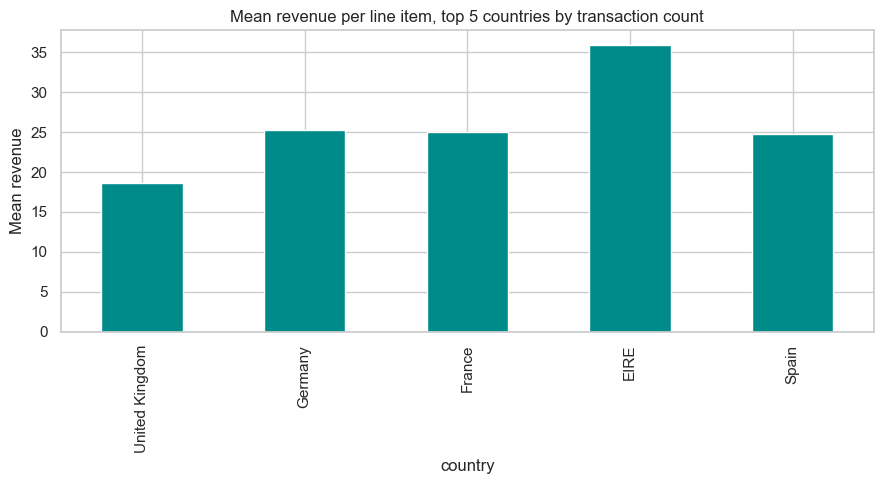

In [10]:
top5_countries = df['country'].value_counts().head(5).index.tolist()
print('Top 5 countries by transaction count:', top5_countries)

top5_df = df[df['country'].isin(top5_countries)]
groups = [top5_df.loc[top5_df['country'] == c, 'revenue'] for c in top5_countries]

f_stat, f_p = stats.f_oneway(*groups)
print(f'F-statistic = {f_stat:.4f}, p-value = {f_p:.6g}')

group_means = top5_df.groupby('country')['revenue'].mean().reindex(top5_countries)
print(group_means)

fig, ax = plt.subplots()
group_means.plot(kind='bar', ax=ax, color='darkcyan')
ax.set_title('Mean revenue per line item, top 5 countries by transaction count')
ax.set_ylabel('Mean revenue')
plt.tight_layout()
plt.show()


**Interpretation.** The top 5 countries by transaction count are the United Kingdom,
Germany, France, EIRE (Ireland), and Spain. The one-way ANOVA gives F = 10.22 with p-value
approximately 2.83 x 10^-8, so we **reject H0** at alpha = 0.05: at least one country's mean
line-item revenue differs from the others. The group means show that **EIRE has by far the
highest mean revenue (GBP 35.93)**, well above Germany (GBP 25.32), France (GBP 24.95), Spain
(GBP 24.79), and the UK (GBP 18.60). The UK's low mean reflects the same volume-of-small-orders
pattern noted in Test 3, while EIRE's high mean points to large wholesale-style orders.
A significant ANOVA only establishes that *some* difference exists; it does not identify which
specific pair(s) differ. A post-hoc Tukey HSD test would be the natural follow-up to make
pairwise comparisons while controlling the family-wise error rate.

---
## Test 5: Association between country and high-value purchase (chi-square test of independence)

**Question:** is the proportion of high-value purchases the same across the main countries?

**Hypotheses:**
- $H_0$: high-value purchase status is independent of country.
- $H_1$: high-value purchase status is associated with country.


In [11]:
# Define "high value" as a line-item revenue at or above the 90th percentile of the full (filtered) dataset.
# This threshold is a modelling choice; it is stated explicitly here and can be changed if a different
# operational definition of "high value" is preferred.
high_value_threshold = df['revenue'].quantile(0.90)
df['high_value'] = df['revenue'] >= high_value_threshold
print(f'High-value threshold (90th percentile of revenue): {high_value_threshold:.2f}')

top5_df = df[df['country'].isin(top5_countries)].copy()
contingency = pd.crosstab(top5_df['country'], top5_df['high_value'])
contingency.columns = ['Not high value', 'High value']
contingency = contingency.reindex(top5_countries)
contingency


High-value threshold (90th percentile of revenue): 32.85


,Not high value,High value
country,,
United Kingdom,442333,42790
Germany,7466,1574
France,7050,1357
EIRE,6271,1619
Spain,2226,258


In [12]:
chi2_stat, chi2_p, dof, expected = stats.chi2_contingency(contingency)
print(f'Chi-square statistic = {chi2_stat:.4f}, degrees of freedom = {dof}, p-value = {chi2_p:.6g}')

expected_df = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
print('\nExpected counts under H0:')
print(expected_df.round(1))


Chi-square statistic = 2489.5197, degrees of freedom = 4, p-value = 0

Expected counts under H0:
                Not high value  High value
country                                   
United Kingdom        440106.6     45016.4
Germany                 8201.1       838.9
France                  7626.9       780.1
EIRE                    7157.9       732.1
Spain                   2253.5       230.5


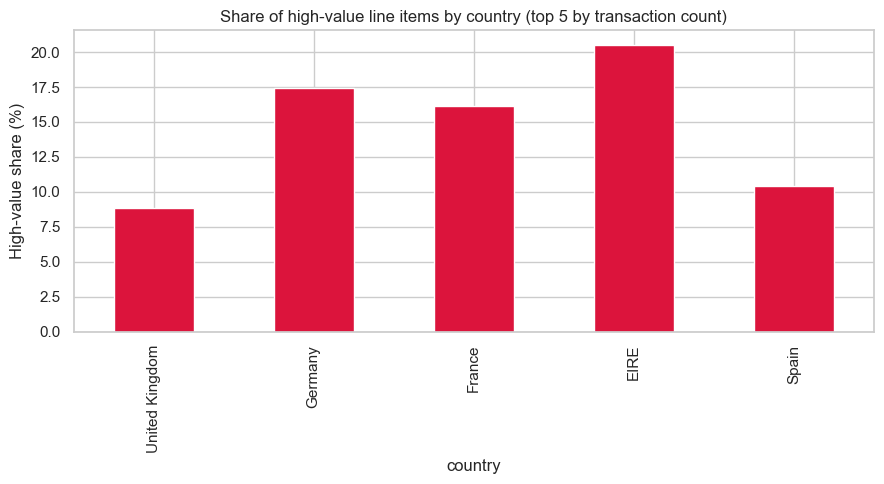

country
United Kingdom     8.82
Germany           17.41
France            16.14
EIRE              20.52
Spain             10.39
dtype: float64

In [13]:
high_value_rate = (contingency['High value'] / contingency.sum(axis=1) * 100).round(2)

fig, ax = plt.subplots()
high_value_rate.plot(kind='bar', ax=ax, color='crimson')
ax.set_title('Share of high-value line items by country (top 5 by transaction count)')
ax.set_ylabel('High-value share (%)')
plt.tight_layout()
plt.show()

high_value_rate


**Interpretation.** The chi-square statistic is 2489.52 with 4 degrees of freedom
and a p-value effectively 0, so we **reject H0** at alpha = 0.05: high-value purchase status is
strongly associated with country. The high-value threshold is revenue >= GBP 32.85 (the 90th
percentile of the filtered dataset). The observed high-value shares are:

| Country | High-value share (%) |
|---|---:|
| United Kingdom | 8.82 |
| Germany | 17.41 |
| France | 16.14 |
| EIRE | 20.52 |
| Spain | 10.39 |

**EIRE** has the highest share of high-value line items (20.5%, well above the 10% expected
under independence), followed by Germany (17.4%) and France (16.1%). The **United Kingdom** has
the lowest share (8.8%, *below* the 10% expected), confirming the pattern from Tests 3 and 4:
UK transactions are numerous but individually small, while the other top countries carry a
disproportionately large share of high-value line items. The effect is large and consistent
across the contingency table.

---
## Test 6: Non-parametric comparison of UK vs other countries (Mann-Whitney U)

**Question:** given that Test 1 established revenue is not normally distributed, do UK and non-UK
line-item revenues differ in their *distributions* (not just their means) using a non-parametric test?

**Hypotheses:**
- $H_0$: the distribution of revenue is the same for UK and non-UK line items (equal medians/ranks).
- $H_1$: the distribution of revenue differs between UK and non-UK line items.

**Rationale:** the two-sample t-test (Test 3) compares means and assumes approximate normality;
Test 1 showed revenue is strongly non-normal, so the Mann-Whitney U test (the non-parametric
counterpart) is a more defensible comparison of central tendency here.

In [14]:
# Mann-Whitney U (a.k.a. Wilcoxon rank-sum) on the same UK vs non-UK split as Test 3.
# This is the non-parametric counterpart to Welch's t-test and does not assume normality.
u_stat, mw_p = stats.mannwhitneyu(uk_revenue, other_revenue, alternative='two-sided')
print(f'Mann-Whitney U statistic = {u_stat:.0f}, p-value = {mw_p:.6g}')
print(f'UK median revenue   = {uk_revenue.median():.2f}')
print(f'Other median revenue = {other_revenue.median():.2f}')

Mann-Whitney U statistic = 5712161120, p-value = 0
UK median revenue   = 8.42
Other median revenue = 17.40


**Interpretation.** The Mann-Whitney U statistic is 5,712,161,120 with a p-value
effectively 0, so we **reject H0** at alpha = 0.05: the distribution of revenue differs between UK
and non-UK line items. The medians tell the story more robustly than the means for this
right-skewed data: the UK median revenue is GBP 8.42 while the non-UK median is GBP 17.40 -
roughly double. This **agrees with Test 3's conclusion** (non-UK revenues are higher), but the
Mann-Whitney test compares the full distributions via ranks rather than just the means, so it
is the more defensible comparison given the strong non-normality established in Test 1. The
fact that both the parametric (t-test) and non-parametric (Mann-Whitney) tests agree gives
confidence that the UK-vs-rest difference is a real feature of the data, not an artifact of the
normality violation.

## Summary of results

| # | Test | Question | Statistic | p-value | Decision at alpha=0.05 |
|---|---|---|---|---|---|
| 1 | Shapiro-Wilk | Is revenue normally distributed? | W = 0.3038 | ~5.97 x 10^-75 | Reject H0 |
| 2 | Spearman | Quantity vs unit price association? | r_s = -0.4032 | ~0 | Reject H0 |
| 3 | Welch's t-test | UK vs other countries, mean revenue? | t = -30.83 | ~5.0 x 10^-208 | Reject H0 |
| 4 | One-way ANOVA | Mean revenue across top 5 countries? | F = 10.22 | ~2.83 x 10^-8 | Reject H0 |
| 5 | Chi-square | High-value purchase vs country? | chi^2 = 2489.52, df=4 | ~0 | Reject H0 |
| 6 | Mann-Whitney U | UK vs other, revenue distribution? | U = 5.71 x 10^9 | ~0 | Reject H0 |

**Overall:** all six null hypotheses are rejected at alpha = 0.05. Revenue is strongly
non-normal (Test 1); quantity and unit price have a significant moderate negative monotone
association (Test 2); UK line items are smaller on average and in distribution than non-UK
ones (Tests 3 and 6); mean revenue differs across the top countries, with EIRE highest and the
UK lowest (Test 4); and high-value purchases are not evenly distributed across countries, with
EIRE over-represented and the UK under-represented (Test 5). The UK-vs-rest finding is robust
across both the parametric (t-test) and non-parametric (Mann-Whitney) comparisons.

